In [1]:
%pip install scipy scikit-image

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
    --------------------------------------- 0.8/37.4 MB 1.3 MB/s eta 0:00:28
   - -------------------------------------- 1.3/37.4 MB 1.7 MB/s eta 0:00:22
   - -------------------------------------- 1.8/37.4 MB 1.9 MB/s eta 0:00:20
   -- ------------------------------------- 2.1/37.4 MB 1.9 MB/s eta 0:00:19
   -- ------------------------------------- 2.6/37.4 MB 1.9 MB/s eta 0:00:19
   --- ------------------------------------ 3.1/37.4 MB 2.0 MB/s eta 0:00:18
   --- ------------------------------------ 3.4/37.4 MB 1.9 MB/s eta 0:00:18
   ---- ----------------------------------- 3.9/37.4 MB 2.0 MB/s eta 0:00:18
   ---- ------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from scipy.fft import dctn, idctn

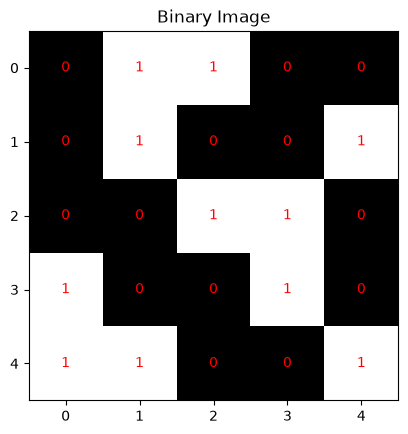

In [3]:
img = np.array([
    [0, 1, 1, 0, 0],
    [0, 1, 0, 0, 1],
    [0, 0, 1, 1, 0],
    [1, 0, 0, 1, 0],
    [1, 1, 0, 0, 1]
])

V = {1}   # set of intensity values used to define adjacency

plt.imshow(img, cmap='gray')
plt.title("Binary Image")
for r in range(img.shape[0]):
    for c in range(img.shape[1]):
        plt.text(c, r, img[r, c], ha='center', va='center', color='red')
plt.show()

In [4]:

def valid(p):
    r, c = p
    return 0 <= r < img.shape[0] and 0 <= c < img.shape[1]

def N4(p):
    r, c = p
    return [q for q in [(r-1,c),(r+1,c),(r,c-1),(r,c+1)] if valid(q)]

def ND(p):
    r, c = p
    return [q for q in [(r-1,c-1),(r-1,c+1),(r+1,c-1),(r+1,c+1)] if valid(q)]

def N8(p):
    return N4(p) + ND(p)

p = (2, 2)
print("Pixel p =", p)
print("N4(p) =", N4(p))
print("ND(p) =", ND(p))
print("N8(p) =", N8(p))

Pixel p = (2, 2)
N4(p) = [(1, 2), (3, 2), (2, 1), (2, 3)]
ND(p) = [(1, 1), (1, 3), (3, 1), (3, 3)]
N8(p) = [(1, 2), (3, 2), (2, 1), (2, 3), (1, 1), (1, 3), (3, 1), (3, 3)]


4-neighbour conectivity,8-neighbour conectivity, m-neighbour conectivity

In [5]:
def adjacent(p, q, mode):
    """Check whether p and q are adjacent (both pixel values must be in V)."""
    if img[p] not in V or img[q] not in V:
        return False
    if mode == 4:
        return q in N4(p)
    if mode == 8:
        return q in N8(p)
    if mode == 'm':
        if q in N4(p):
            return True
        if q in ND(p):
            common = set(N4(p)) & set(N4(q))
            # no common 4-neighbour may have a value in V
            return not any(img[x] in V for x in common)
    return False

def find_path(src, dst, mode):
    """BFS: returns a path if src and dst are connected, else None."""
    if img[src] not in V or img[dst] not in V:
        return None
    queue = deque([[src]])
    visited = {src}
    while queue:
        path = queue.popleft()
        cur = path[-1]
        if cur == dst:
            return path
        for nb in N8(cur):
            if nb not in visited and adjacent(cur, nb, mode):
                visited.add(nb)
                queue.append(path + [nb])
    return None

src, dst = (0, 1), (3, 3)
for mode, name in [(4, "4-connectivity"), (8, "8-connectivity"), ('m', "m-connectivity")]:
    path = find_path(src, dst, mode)
    print(f"{name}: {'Connected' if path else 'Not connected'}")
    print("   Path:", path)

4-connectivity: Not connected
   Path: None
8-connectivity: Connected
   Path: [(0, 1), (1, 1), (2, 2), (3, 3)]
m-connectivity: Connected
   Path: [(0, 1), (1, 1), (2, 2), (2, 3), (3, 3)]


. Euclidean distance

 City-block distance

. Chessboard distance

In [6]:
def euclidean(p, q):
    return np.sqrt((p[0]-q[0])**2 + (p[1]-q[1])**2)

def city_block(p, q):          # D4
    return abs(p[0]-q[0]) + abs(p[1]-q[1])

def chessboard(p, q):          # D8
    return max(abs(p[0]-q[0]), abs(p[1]-q[1]))

p, q = (0, 1), (3, 3)
print(f"p = {p}, q = {q}")
print("Euclidean distance      :", round(euclidean(p, q), 3))
print("City-block (D4) distance:", city_block(p, q))
print("Chessboard (D8) distance:", chessboard(p, q))

p = (0, 1), q = (3, 3)
Euclidean distance      : 3.606
City-block (D4) distance: 5
Chessboard (D8) distance: 3


Visualise the path

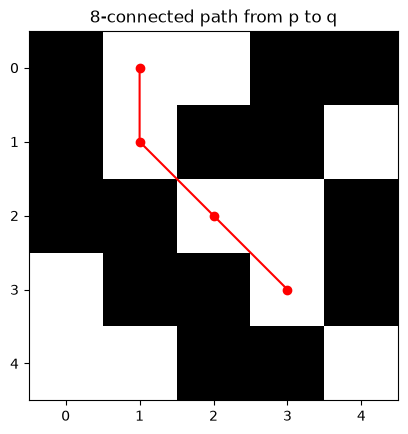

In [7]:
path = find_path(src, dst, 8)
plt.imshow(img, cmap='gray')
if path:
    ys, xs = zip(*path)
    plt.plot(xs, ys, 'r-o')
plt.title("8-connected path from p to q")
plt.show()

Q2

Load a grayscale image

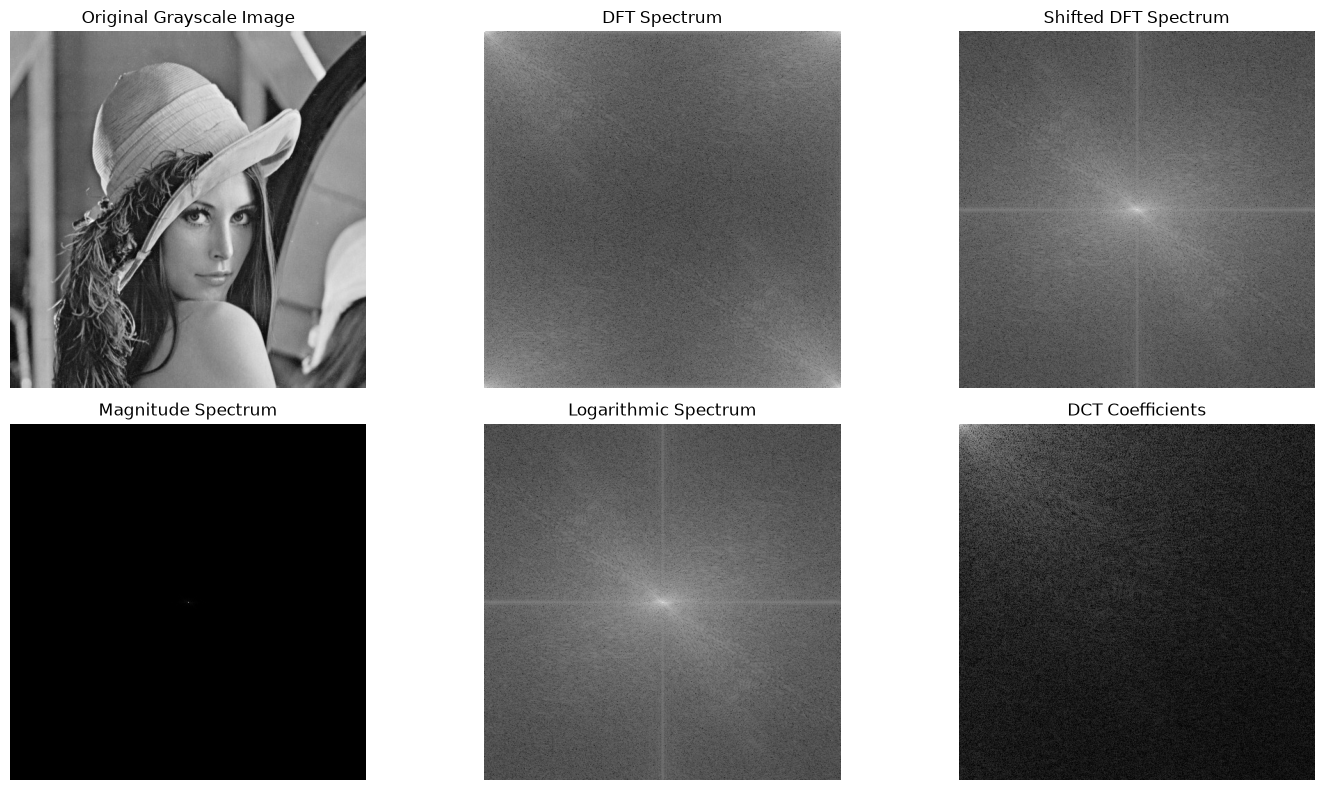

In [8]:
import os
import urllib.request
import cv2
import matplotlib.pyplot as plt
import numpy as np

image_path = "lenna.png"

# Auto-download Lenna image if missing locally
if not os.path.exists(image_path):
    print("Downloading sample Lenna image...")
    url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
    urllib.request.urlretrieve(url, image_path)

# Read image
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# --------------------------------------------------
# a. Calculate 2-D Discrete Fourier Transform (DFT)
# --------------------------------------------------
dft = np.fft.fft2(img)

# --------------------------------------------------
# b. Shift zero-frequency component to center
# --------------------------------------------------
dft_shifted = np.fft.fftshift(dft)

# --------------------------------------------------
# c. Calculate magnitude spectrum
# --------------------------------------------------
magnitude = np.abs(dft_shifted)

# --------------------------------------------------
# d. Apply logarithmic scaling
# --------------------------------------------------
log_magnitude = np.log(1 + magnitude)

log_magnitude_display = cv2.normalize(
    log_magnitude, None, 0, 255, cv2.NORM_MINMAX
)
log_magnitude_display = np.uint8(log_magnitude_display)

# --------------------------------------------------
# e. Calculate 2-D Discrete Cosine Transform (DCT)
# --------------------------------------------------
img_float = np.float32(img)
dct = cv2.dct(img_float)

# --------------------------------------------------
# Display results
# --------------------------------------------------
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(np.log(1 + np.abs(dft)), cmap="gray")
plt.title("DFT Spectrum")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(np.log(1 + np.abs(dft_shifted)), cmap="gray")
plt.title("Shifted DFT Spectrum")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(magnitude, cmap="gray")
plt.title("Magnitude Spectrum")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(log_magnitude_display, cmap="gray")
plt.title("Logarithmic Spectrum")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(np.log(1 + np.abs(dct)), cmap="gray")
plt.title("DCT Coefficients")
plt.axis("off")

plt.tight_layout()
plt.show()